
# AF7 – Proyecto final
## Simulación de un robot manipulador planar de 2 GDL

Este notebook implementa el modelo dinámico obtenido mediante Euler–Lagrange:

\[
\tau=M(q)\ddot q+C(q,\dot q)\dot q+g(q)+f(\dot q)
\]

con:

\[
q=
\begin{bmatrix}
q_1\\
q_2
\end{bmatrix}
\]

La simulación se realiza durante **10 segundos** y permite visualizar la posición de las dos articulaciones.

> **Nota:** La actividad no fija condiciones iniciales ni una función de torque específica. Para comprobar el funcionamiento del modelo se emplea un caso de prueba editable con condiciones iniciales en cero y torques sinusoidales.



## 1. Parámetros del robot

Los parámetros utilizados son los mismos empleados en el desarrollo matemático:

- \(m_1=23.902\) kg
- \(m_2=3.88\) kg
- \(l_1=l_2=0.45\) m
- \(l_{c1}=0.091\) m
- \(l_{c2}=0.048\) m
- \(I_1=1.266\) kg·m²
- \(I_2=0.093\) kg·m²
- \(b_1=2.288\) N·m·s/rad
- \(b_2=0.175\) N·m·s/rad
- \(f_{c1}=7.17\) N·m
- \(f_{c2}=1.734\) N·m
- \(f_{e1}=8.8\) N·m
- \(f_{e2}=1.87\) N·m
- \(g=9.81\) m/s²


In [1]:

import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import solve_ivp

# Parámetros del eslabón 1
m1 = 23.902
l1 = 0.45
lc1 = 0.091
I1 = 1.266
b1 = 2.288
fc1 = 7.17
fe1 = 8.8

# Parámetros del eslabón 2
m2 = 3.88
l2 = 0.45
lc2 = 0.048
I2 = 0.093
b2 = 0.175
fc2 = 1.734
fe2 = 1.87

g = 9.81

# Término recurrente del modelo
h = m2 * l1 * lc2

print("Parámetros cargados correctamente.")
print(f"h = m2*l1*lc2 = {h:.6f}")


Parámetros cargados correctamente.
h = m2*l1*lc2 = 0.083808



## 2. Matriz de inercia \(M(q)\)

\[
M(q)=
\begin{bmatrix}
M_{11} & M_{12}\\
M_{12} & M_{22}
\end{bmatrix}
\]

donde:

\[
M_{11}=m_1l_{c1}^2+m_2l_1^2+m_2l_{c2}^2+2m_2l_1l_{c2}\cos(q_2)+I_1+I_2
\]

\[
M_{12}=m_2l_{c2}^2+m_2l_1l_{c2}\cos(q_2)+I_2
\]

\[
M_{22}=m_2l_{c2}^2+I_2
\]


In [2]:

def matriz_inercia(q):
    q1, q2 = q

    M11 = (
        m1*lc1**2
        + m2*l1**2
        + m2*lc2**2
        + 2*h*np.cos(q2)
        + I1 + I2
    )

    M12 = m2*lc2**2 + h*np.cos(q2) + I2
    M22 = m2*lc2**2 + I2

    return np.array([
        [M11, M12],
        [M12, M22]
    ])



## 3. Matriz de Coriolis y términos centrífugos \(C(q,\dot q)\)

\[
C(q,\dot q)=
\begin{bmatrix}
-2h\sin(q_2)\dot q_2 & -h\sin(q_2)\dot q_2\\
h\sin(q_2)\dot q_1 & 0
\end{bmatrix}
\]


In [3]:

def matriz_coriolis(q, qd):
    q1, q2 = q
    qd1, qd2 = qd

    s2 = np.sin(q2)

    return np.array([
        [-2*h*s2*qd2, -h*s2*qd2],
        [ h*s2*qd1,    0.0]
    ])



## 4. Vector de gravedad \(g(q)\)

\[
g(q)=g
\begin{bmatrix}
(m_1l_{c1}+m_2l_1)\sin(q_1)+m_2l_{c2}\sin(q_1+q_2)\\
m_2l_{c2}\sin(q_1+q_2)
\end{bmatrix}
\]


In [4]:

def vector_gravedad(q):
    q1, q2 = q

    G1 = g * (
        (m1*lc1 + m2*l1)*np.sin(q1)
        + m2*lc2*np.sin(q1 + q2)
    )

    G2 = g * m2*lc2*np.sin(q1 + q2)

    return np.array([G1, G2])



## 5. Fricción

En el desarrollo se consideró fricción viscosa, de Coulomb y estática.

Para la simulación numérica se reemplaza `sign(·)` por una aproximación suave con `tanh`, evitando discontinuidades que dificulten la integración numérica.

La forma implementada conserva:

- fricción viscosa;
- fricción de Coulomb;
- una contribución de fricción estática próxima a velocidad cero.


In [5]:

def vector_friccion(qd, tau, k=50.0):
    qd = np.asarray(qd)
    tau = np.asarray(tau)

    # Aproximación suave de sign(qdot)
    signo_suave = np.tanh(k * qd)

    viscosa = np.array([b1, b2]) * qd
    coulomb = np.array([fc1, fc2]) * signo_suave

    # Aproximación del término de fricción estática cerca de qdot = 0
    limite_estatico = np.array([fe1, fe2])
    tau_saturado = np.clip(tau, -limite_estatico, limite_estatico)
    estatica = (1.0 - np.abs(signo_suave)) * tau_saturado

    return viscosa + coulomb + estatica



## 6. Torque aplicado por los motores

Como caso de prueba se emplean:

\[
\tau_1(t)=12\sin(0.8t)
\]

\[
\tau_2(t)=3\sin(1.2t)
\]

Estos valores **no son datos impuestos por el enunciado**; únicamente permiten observar la respuesta del modelo y pueden modificarse fácilmente.


In [6]:

def torque_motor(t):
    tau1 = 12.0 * np.sin(0.8 * t)
    tau2 = 3.0 * np.sin(1.2 * t)
    return np.array([tau1, tau2])



## 7. Representación en variables de estado

Se define:

\[
x=
\begin{bmatrix}
q_1\\
q_2\\
\dot q_1\\
\dot q_2
\end{bmatrix}
\]

Despejando la aceleración:

\[
\ddot q=
M(q)^{-1}
\left[
\tau-C(q,\dot q)\dot q-g(q)-f(\dot q)
\right]
\]

y por lo tanto:

\[
\dot x=
\begin{bmatrix}
\dot q_1\\
\dot q_2\\
\ddot q_1\\
\ddot q_2
\end{bmatrix}
\]


In [7]:

def modelo_robot(t, x):
    q = x[0:2]
    qd = x[2:4]

    tau = torque_motor(t)
    M = matriz_inercia(q)
    C = matriz_coriolis(q, qd)
    G = vector_gravedad(q)
    F = vector_friccion(qd, tau)

    # M(q) qdd = tau - C(q,qd)qd - G(q) - F(qd)
    qdd = np.linalg.solve(M, tau - C @ qd - G - F)

    return np.concatenate((qd, qdd))



## 8. Condiciones iniciales y simulación

Caso de prueba:

\[
q_1(0)=0,\quad q_2(0)=0
\]

\[
\dot q_1(0)=0,\quad \dot q_2(0)=0
\]

Tiempo total:

\[
0\leq t\leq10\;s
\]


In [8]:

# Condiciones iniciales
x0 = [0.0, 0.0, 0.0, 0.0]

# Tiempo
ti = 0.0
tf = 10.0
t_eval = np.linspace(ti, tf, 2001)

sol = solve_ivp(
    modelo_robot,
    [ti, tf],
    x0,
    t_eval=t_eval,
    method="RK45",
    max_step=0.02,
    rtol=1e-5,
    atol=1e-7
)

if not sol.success:
    raise RuntimeError(sol.message)

t = sol.t
q1 = sol.y[0]
q2 = sol.y[1]
qd1 = sol.y[2]
qd2 = sol.y[3]

q1_deg = np.rad2deg(q1)
q2_deg = np.rad2deg(q2)
qd1_deg = np.rad2deg(qd1)
qd2_deg = np.rad2deg(qd2)

print("Simulación terminada correctamente.")
print(f"Tiempo final: {t[-1]:.1f} s")


Simulación terminada correctamente.
Tiempo final: 10.0 s



## 9. Posición de las articulaciones


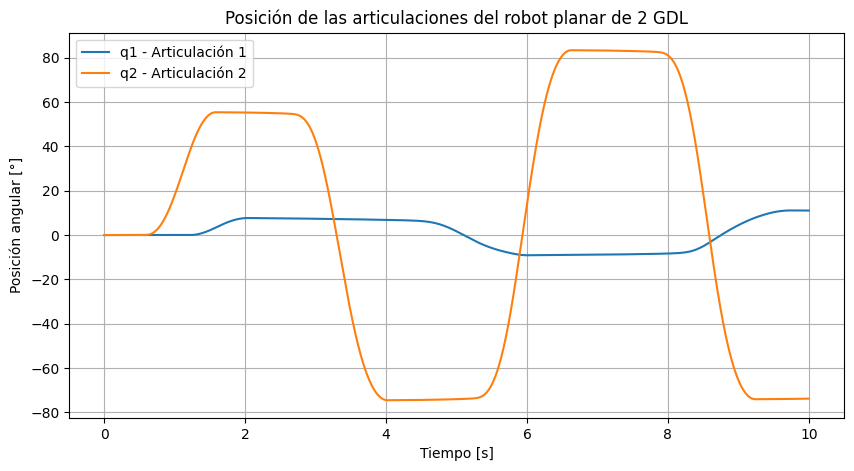

In [9]:

plt.figure(figsize=(10, 5))
plt.plot(t, q1_deg, label="q1 - Articulación 1")
plt.plot(t, q2_deg, label="q2 - Articulación 2")
plt.xlabel("Tiempo [s]")
plt.ylabel("Posición angular [°]")
plt.title("Posición de las articulaciones del robot planar de 2 GDL")
plt.grid(True)
plt.legend()
plt.show()



## 10. Velocidad de las articulaciones

Esta gráfica es complementaria; el requisito mínimo de la actividad es visualizar la posición.


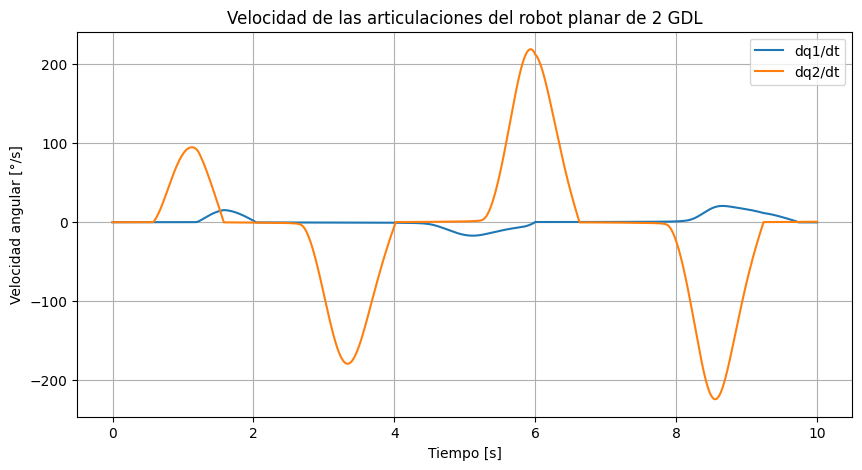

In [10]:

plt.figure(figsize=(10, 5))
plt.plot(t, qd1_deg, label="dq1/dt")
plt.plot(t, qd2_deg, label="dq2/dt")
plt.xlabel("Tiempo [s]")
plt.ylabel("Velocidad angular [°/s]")
plt.title("Velocidad de las articulaciones del robot planar de 2 GDL")
plt.grid(True)
plt.legend()
plt.show()



## 11. Resultados principales


In [11]:

print("Rangos obtenidos en el caso de prueba:")
print(f"q1: {q1_deg.min():.2f}° a {q1_deg.max():.2f}°")
print(f"q2: {q2_deg.min():.2f}° a {q2_deg.max():.2f}°")
print(f"dq1/dt: {qd1_deg.min():.2f}°/s a {qd1_deg.max():.2f}°/s")
print(f"dq2/dt: {qd2_deg.min():.2f}°/s a {qd2_deg.max():.2f}°/s")


Rangos obtenidos en el caso de prueba:
q1: -9.11° a 11.10°
q2: -74.51° a 83.37°
dq1/dt: -17.03°/s a 20.60°/s
dq2/dt: -224.09°/s a 218.99°/s



## 12. Conclusión de la simulación

Se implementó el modelo dinámico del robot manipulador planar de dos grados de libertad en su forma matricial:

\[
\tau=M(q)\ddot q+C(q,\dot q)\dot q+g(q)+f(\dot q)
\]

La ecuación se transformó a variables de estado y fue resuelta numéricamente mediante `solve_ivp` durante 10 segundos. La simulación permite visualizar la evolución de \(q_1\) y \(q_2\), considerando los efectos de inercia, Coriolis, gravedad y fricción.

Los torques utilizados corresponden a un caso de prueba para verificar el funcionamiento del modelo y pueden sustituirse por otros perfiles de entrada sin modificar las ecuaciones dinámicas.



## 13. Referencias

- Cortés, F. R. (2020). *Robótica: control de robots manipuladores*. Marcombo.
- Desarrollo matemático de la AF7 – Proyecto Final, Modelado y Simulación de Sistemas Mecatrónicos.
- SciPy Community. *solve_ivp — SciPy documentation*.
- NumPy Developers. *NumPy documentation*.
- Matplotlib Development Team. *Matplotlib documentation*.
